# Imports

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import keras
import numpy as np
import pandas as pd
import transformers
# import tensorflow as tf
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Dataset

Get the dataset from [here](https://tatoeba.org/en/downloads). Preferably use russian to english translations.

In [2]:
dataset = pd.read_csv('dataset.tsv', sep='\t', header=None, usecols=[1, 3])
len(dataset)

830696

In [3]:
dataset.head()

,1,3
0,Один раз в жизни я делаю хорошее дело... И оно...,For once in my life I'm doing a good deed... A...
1,Давайте что-нибудь попробуем!,Let's try something.
2,Мне пора идти спать.,I have to go to sleep.
3,Что ты делаешь?,What are you doing?
4,Что ты делаешь?,What do you make?


In [4]:
dataset[-10:]

,1,3
830686,"Поверить не могу, что уже Рождество.",I can't believe it's Christmas already.
830687,Я ничего не готовила.,I wasn't cooking anything.
830688,Я ничего не готовил.,I wasn't cooking anything.
830689,Я сегодня не буду готовить.,Today I will not cook.
830690,Мне нужна сумка. Можете одолжить?,I need a bag. Will you lend me one?
830691,Мне нужна сумка. Можешь одолжить?,I need a bag. Will you lend me one?
830692,Мне нравятся шахматы.,I like chess.
830693,Она пожаловалась ему на еду.,She complained to him about the food.
830694,Все персонажи легко узнаваемы.,All the characters are easily recognizable.
830695,"«Кто эта женщина в белом платье?» — «Это Мэри,...","Who is the lady in the white dress? ""It's Mary..."


In [5]:
dataset[1].unique()

<ArrowStringArray>
[                                            'Один раз в жизни я делаю хорошее дело... И оно бесполезно.',
                                                                          'Давайте что-нибудь попробуем!',
                                                                                   'Мне пора идти спать.',
                                                                                        'Что ты делаешь?',
                                                                                               'Что это?',
                                                           'Сегодня 18 июня, и это день рождения Мюриэл!',
                                                                               'С днём рождения, Мюриэл!',
                                                                                      'Мюриэл сейчас 20.',
                                                                                      'Пароль «Muiriel».',
                  

In [6]:
X = dataset.groupby(1, as_index=False).first()

Use a custom tokenizer that can add bos and eos tokens (pass `add_special_tokens=True` when calling the tokenizer to add them).

In [7]:
# class Tokenizer(transformers.GPT2Tokenizer):

#     def build_inputs_with_special_tokens(self, token_ids_0, token_ids_1=None):
#         if token_ids_1 is None:
#             return [self.bos_token_id, *token_ids_0, self.eos_token_id]

#         return [self.bos_token_id, *token_ids_0, self.bos_token_id, *token_ids_1, self.eos_token_id]

In [2]:
en_tokenizer = transformers.AutoTokenizer.from_pretrained('mjbommar/ogbert-tokenizer-8k', cache_dir='../en_tokenizer')
ru_tokenizer = transformers.AutoTokenizer.from_pretrained('flexitok/bpe_rus_Cyrl_8000', cache_dir='../ru_tokenizer')


In [9]:
en_tokenizer.pad_token_id, en_tokenizer.eos_token_id, en_tokenizer.bos_token_id, ru_tokenizer.pad_token_id, ru_tokenizer.eos_token_id, ru_tokenizer.bos_token_id

(2, 1, 0, 3, 2, 1)

In [10]:
ru_raw = [np.array(ru_tokenizer.encode(i), dtype=np.int16) for i in tqdm(X[1])]
en_raw = [np.array([en_tokenizer.bos_token_id, *en_tokenizer.encode(i), en_tokenizer.eos_token_id], dtype=np.int16) for i in tqdm(X[3])]

ru = [seq + 1 for seq in ru_raw]
en = [seq + 1 for seq in en_raw]

  0%|          | 0/711733 [00:00<?, ?it/s]

100%|██████████| 711733/711733 [00:28<00:00, 25028.95it/s]


In [11]:
token_ru_avg_len = np.mean([len(t) for t in ru])
token_en_avg_len = np.mean([len(t) for t in en])

symbol_ru_avg_len = np.mean(X[1].str.len())
symbol_en_avg_len = np.mean(X[3].str.len())

(token_ru_avg_len, symbol_ru_avg_len), (token_en_avg_len, symbol_en_avg_len)

((np.float64(10.126620516401516), np.float64(31.42405789811629)),
 (np.float64(18.638812588428525), np.float64(31.799566691441875)))

In [12]:
ru_len = np.array([len(i) for i in ru])
en_len = [len(i) for i in en]

0

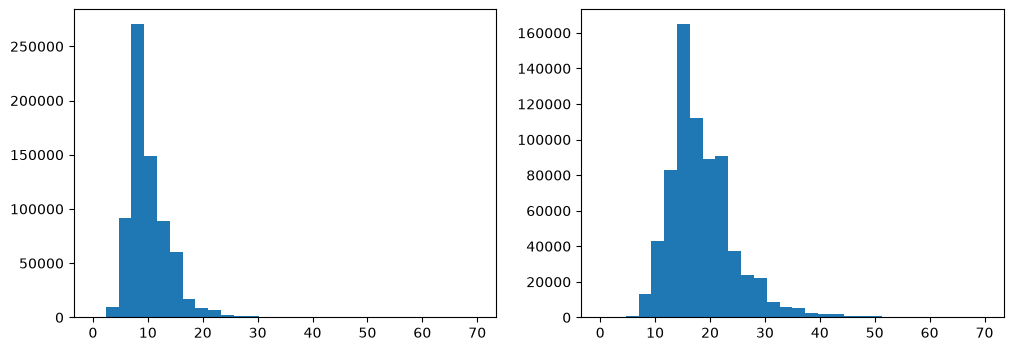

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(ru_len, range=(0, 70), bins=30)
ax[1].hist(en_len, range=(0, 70), bins=30)
0

Since the dataset is rather large, you can omit the validation dataset and just use a set of test sentences after the training.

Create a dataset that returns the following
* A pair of tensors `((None, L), (None, P))` -- input sequence of tokens and output sequence of tokens to be fed into decoder (this should start with the BOS token)
* A tensor `(None, P)` -- output sequence of tokens to be predicted (this should end with EOS token)
* A tensor `(None, P)` -- a masking tensor marking padded tokens with 0

In [14]:
class DefaultDataset(keras.utils.PyDataset):
    def __init__(self, X, y, shuffle=False, batch_size=128, seed=1, **kwargs):
        super().__init__(**kwargs)
        self.X = X
        self.y = y
        self.shuffle = shuffle
        self.batch_size = batch_size
        self.rng = np.random.default_rng(seed)
        self.idx = np.arange(len(self.X))
        self.X_lens = np.array([len(e) for e in self.X])
        self.y_lens = np.array([len(e) for e in self.y])

        self.on_epoch_end()

    def __len__(self):
        return -(-len(self.X) // self.batch_size)

    def __getitem__(self, ind):
        i = self.idx[ind * self.batch_size: (ind + 1) * self.batch_size]

        x = keras.utils.pad_sequences(
            [self.X[e] for e in i], 
            maxlen=100,
            padding='post',
            truncating='post',
            value=0
        )

        y = keras.utils.pad_sequences(
            [self.y[e] for e in i], 
            maxlen=100,
            padding='post',
            truncating='post',
            value=0
        )

        target = y[:, 1:]

        mask = (target != 0).astype('float32')

        return (
            {'Encoder_input': x, 'Decoder_input': y[:, :-1]},
            target,
            mask
        )

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.idx)


In [15]:
X_train, X_val, y_train, y_val = train_test_split(ru, en, test_size=0.05)

In [16]:
default_dataset = DefaultDataset(X_train, y_train, batch_size=128, shuffle=True)

val_dataset = DefaultDataset(X_val, y_val, batch_size=128, shuffle=False)

# Model

Create a model for training. The model should have two inputs: input sequence `(None, L)` and output sequence`(None, P)`. The model output is a single tensor `(None, P)` logits (or probabilities) of the next token predicted for each input one.

In [3]:
@keras.saving.register_keras_serializable()
class Seq2Seq(keras.Model):
    def __init__(self, units: int, n_tokens_x: int, n_labels: int, n_stacks: int = 1, bidirectional: bool = False, 
                 embed_size: int = 128, cell_type: str = 'LSTMCell', dropout: float = 0.0, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.n_tokens_x = n_tokens_x
        self.n_labels = n_labels
        self.n_stacks = n_stacks
        self.bidirectional = bidirectional
        self.embed_size = embed_size
        self.dropout = dropout

        if cell_type == 'LSTMCell':
            self.cell_type = keras.layers.LSTMCell
        else:
            self.cell_type = keras.layers.GRUCell

        # Encoder
        self.encoder_input = keras.layers.Input(shape=(None,), name='Encoder_input', dtype='int16')
        self.encoder_embedding_layer_ru = keras.layers.Embedding(n_tokens_x, embed_size, mask_zero=True)

        x = self.encoder_embedding_layer_ru(self.encoder_input)
        if not bidirectional:
            layers = [self.cell_type(units=units, dropout=self.dropout) for _ in range(n_stacks)]
            stacked_encoder = keras.layers.StackedRNNCells(layers)
            x = keras.layers.RNN(stacked_encoder)(x)
        else:
            for i in range(n_stacks):
                is_not_last = i != n_stacks - 1
                layer = keras.layers.RNN(self.cell_type(units=units, dropout=self.dropout), return_sequences=is_not_last)
                x = keras.layers.Bidirectional(layer)(x)

        self.encoder_output = x

        # Decoder
        self.decoder_input = keras.layers.Input(shape=(None,), name='Decoder_input', dtype='int16')
        self.decoder_embedding_layer_en = keras.layers.Embedding(n_labels, embed_size)

        x = self.decoder_embedding_layer_en(self.decoder_input)
        context = keras.layers.Lambda(
            lambda x: keras.ops.repeat(x[0][:, None, :], keras.ops.shape(x[1])[1], axis=1),
        )([self.encoder_output, self.decoder_input])
        emb_and_context = keras.layers.Concatenate(axis=-1)([x, context])

        layers = [self.cell_type(units=units, dropout=self.dropout) for _ in range(n_stacks)]
        self.decoder_stacked_layers = keras.layers.StackedRNNCells(layers)
        self.decoder_rnn = keras.layers.RNN(self.decoder_stacked_layers, return_sequences=True)
        x = self.decoder_rnn(emb_and_context)

        self.out_dense = keras.layers.Dense(n_labels)
        x = self.out_dense(x)

        # Models
        # Train model
        self.train_model = keras.Model(
            inputs=[self.encoder_input, self.decoder_input],
            outputs=x,
            name='train_model'
        )

        # Encoder model
        self.encoder_model = keras.Model(
            inputs=self.encoder_input,
            outputs=self.encoder_output,
            name='encoder_model'
        )

        # Decoder step model
        state_sizes = self.decoder_stacked_layers.state_size
        encoder_units = keras.ops.shape(self.encoder_output)[-1]

        token_input = keras.Input(shape=(), dtype='int16', name='Input_token')
        ctx_input = keras.Input(shape=(encoder_units,), name='Input_context')
        state_inputs = [keras.Input(shape=(s,)) for s in state_sizes]

        emb = self.decoder_embedding_layer_en(token_input)
        step_input = keras.layers.Concatenate(axis=-1)([emb, ctx_input])
        step, new_states = self.decoder_stacked_layers(step_input, state_inputs)
        if not isinstance(new_states, (list, tuple)):
            new_states = [new_states]

        logits = self.out_dense(step)

        self.decoder_step_model = keras.Model(
            inputs=[token_input, ctx_input, *state_inputs],
            outputs=[logits, *new_states],
            name='decoder_step_model',
        )

    def call(self, inputs, training=False):
        return self.train_model(inputs, training=training)

    def get_config(self):
        config = super().get_config()
        config.update({
            'units': self.units, 
            'n_tokens_x': self.n_tokens_x,
            'n_labels': self.n_labels, 
            'n_stacks': self.n_stacks, 
            'bidirectional': self.bidirectional, 
            'embed_size': self.embed_size, 
            'cell_type': 'LSTMCell' if self.cell_type is keras.layers.LSTMCell else 'GRUCell', 
            'dropout': self.dropout
        })
        return config

    def translate(self, text, ru_tokenizer, en_tokenizer, max_len=100):
        t = np.array(ru_tokenizer.encode(text), dtype='int16')[None] + 1
        ru_context = self.encoder_model(keras.ops.convert_to_tensor(t, dtype='int16'))

        states = [keras.ops.zeros((1, s), dtype='float32') for s in self.decoder_stacked_layers.state_size]

        loc_token_id = en_tokenizer.bos_token_id + 1
        output = []

        for i in range(max_len):
            loc_token = keras.ops.convert_to_tensor([loc_token_id], dtype='int16')
            logit, *states = self.decoder_step_model([loc_token, ru_context, *states])

            new_token_id = int(keras.ops.argmax(logit, axis=-1)[0])

            if new_token_id == 0 or new_token_id - 1 == en_tokenizer.eos_token_id:
                break

            output.append(new_token_id - 1)
            loc_token_id = new_token_id

        return en_tokenizer.decode(output)

Try to add attention to your model (for example [additive attention](https://keras.io/api/layers/attention_layers/additive_attention/)), does it perform better?

In [4]:
@keras.saving.register_keras_serializable()
class Seq2SeqAttention(keras.Model):
    def __init__(self, units: int, n_tokens_x: int, n_labels: int, n_stacks: int = 1, bidirectional: bool = False, 
                 embed_size: int = 128, cell_type: str = 'LSTMCell', dropout: float = 0.0, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.n_tokens_x = n_tokens_x
        self.n_labels = n_labels
        self.n_stacks = n_stacks
        self.bidirectional = bidirectional
        self.embed_size = embed_size
        self.dropout = dropout

        self.attention = keras.layers.AdditiveAttention()

        if cell_type == 'LSTMCell':
            self.cell_type = keras.layers.LSTMCell
        else:
            self.cell_type = keras.layers.GRUCell

        # Encoder
        self.encoder_input = keras.layers.Input(shape=(None,), name='Encoder_input', dtype='int16')
        self.encoder_embedding_layer_ru = keras.layers.Embedding(n_tokens_x, embed_size, mask_zero=True)

        x = self.encoder_embedding_layer_ru(self.encoder_input)
        if not bidirectional:
            layers = [self.cell_type(units=units, dropout=self.dropout) for _ in range(n_stacks)]
            stacked_encoder = keras.layers.StackedRNNCells(layers)
            x = keras.layers.RNN(stacked_encoder, return_sequences=True)(x)
        else:
            for i in range(n_stacks):
                is_not_last = i != n_stacks - 1
                layer = keras.layers.RNN(self.cell_type(units=units, dropout=self.dropout), return_sequences=True)
                x = keras.layers.Bidirectional(layer)(x)

        self.encoder_proj  = keras.layers.Dense(units)
        self.encoder_output = self.encoder_proj(x)

        # Decoder
        self.decoder_input = keras.layers.Input(shape=(None,), name='Decoder_input', dtype='int16')
        self.decoder_embedding_layer_en = keras.layers.Embedding(n_labels, embed_size)

        x = self.decoder_embedding_layer_en(self.decoder_input)

        layers = [self.cell_type(units=units, dropout=self.dropout) for _ in range(n_stacks)]
        self.decoder_stacked_layers = keras.layers.StackedRNNCells(layers)
        self.decoder_rnn = keras.layers.RNN(self.decoder_stacked_layers, return_sequences=True)
        x = self.decoder_rnn(x)

        x = self.attention([x, self.encoder_output])

        self.out_dense = keras.layers.Dense(n_labels)
        x = self.out_dense(x)

        # Models
        # Train model
        self.train_model = keras.Model(
            inputs=[self.encoder_input, self.decoder_input],
            outputs=x,
            name='train_model'
        )

        # Encoder model
        self.encoder_model = keras.Model(
            inputs=self.encoder_input,
            outputs=self.encoder_output,
            name='encoder_model'
        )

        # Decoder step model
        state_sizes = self.decoder_stacked_layers.state_size
        encoder_units = keras.ops.shape(self.encoder_output)[-1]

        token_input = keras.Input(shape=(), dtype='int16', name='Input_token')
        enc_seq_input = keras.Input(shape=(None, encoder_units), name='Input_encoder_seq')
        state_inputs = [keras.Input(shape=(s,)) for s in state_sizes]

        emb = self.decoder_embedding_layer_en(token_input)
        step, new_states = self.decoder_stacked_layers(emb, state_inputs)
        if not isinstance(new_states, (list, tuple)):
            new_states = [new_states]

        query = keras.ops.expand_dims(step, axis=1)
        step = self.attention([query, enc_seq_input])
        step = keras.ops.squeeze(step, axis=1)

        logits = self.out_dense(step)

        self.decoder_step_model = keras.Model(
            inputs=[token_input, enc_seq_input, *state_inputs],
            outputs=[logits, *new_states],
            name='decoder_step_model',
        )

    def call(self, inputs, training=False):
        return self.train_model(inputs, training=training)

    def get_config(self):
        config = super().get_config()
        config.update({
            'units': self.units, 
            'n_tokens_x': self.n_tokens_x,
            'n_labels': self.n_labels, 
            'n_stacks': self.n_stacks, 
            'bidirectional': self.bidirectional, 
            'embed_size': self.embed_size, 
            'cell_type': 'LSTMCell' if self.cell_type is keras.layers.LSTMCell else 'GRUCell', 
            'dropout': self.dropout
        })
        return config

    def translate(self, text, ru_tokenizer, en_tokenizer, max_len=100):
        t = np.array(ru_tokenizer.encode(text), dtype='int16')[None] + 1
        ru_context = self.encoder_model(keras.ops.convert_to_tensor(t, dtype='int16'))

        states = [keras.ops.zeros((1, s), dtype='float32') for s in self.decoder_stacked_layers.state_size]

        loc_token_id = en_tokenizer.bos_token_id + 1
        output = []

        for i in range(max_len):
            loc_token = keras.ops.convert_to_tensor([loc_token_id], dtype='int16')
            logit, *states = self.decoder_step_model([loc_token, ru_context, *states])

            new_token_id = int(keras.ops.argmax(logit, axis=-1)[0])

            if new_token_id == 0 or new_token_id - 1 == en_tokenizer.eos_token_id:
                break

            output.append(new_token_id - 1)
            loc_token_id = new_token_id

        return en_tokenizer.decode(output)

# Training

Train your model using teacher forcing. The idea is that the model predicts the next token that should follow, so one part of the model (called encoder) reads the text and output some state containing information about the text read. The other part of the model (called decoder) reads an already generated text (or in case of the teacher forcing the expected output) and predicts the next token for each one. 

In [ ]:
model = Seq2Seq(
    300,
    len(ru_tokenizer) + 1,
    len(en_tokenizer) + 1,
    3,
    True,
    150,
    'GRUCell',
)

model.compile(
    optimizer=keras.optimizers.Adam(clipnorm=1.),
    loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=True,
            ignore_class=0
        ),
    metrics=[
        'sparse_categorical_crossentropy',
    ]
)

: 

In [ ]:
# model.fit(
#     default_dataset,
#     validation_data=val_dataset,
#     epochs=5,
#     callbacks=[
#         keras.callbacks.ModelCheckpoint(f'GRU_model.keras', monitor='val_loss', mode='min', save_best_only=True)
#     ]
# )

Epoch 1/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 651s 3s/step - loss: 5.3563 - sparse_categorical_crossentropy: 10.1045 - val_loss: 4.6659 - val_sparse_categorical_crossentropy: 10.0600
Epoch 2/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 653s 3s/step - loss: 4.6098 - sparse_categorical_crossentropy: 10.0376 - val_loss: 4.5644 - val_sparse_categorical_crossentropy: 10.0048
Epoch 3/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 650s 3s/step - loss: 4.5266 - sparse_categorical_crossentropy: 9.9986 - val_loss: 4.5121 - val_sparse_categorical_crossentropy: 9.9755


In [33]:
model_attention = Seq2SeqAttention(
    300,
    len(ru_tokenizer) + 1,
    len(en_tokenizer) + 1,
    3,
    True,
    150,
    'GRUCell',
)

model_attention.compile(
    optimizer=keras.optimizers.Adam(clipnorm=1.),
    loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=True,
            ignore_class=0
        ),
    metrics=[
        'sparse_categorical_crossentropy',
    ]
)

In [ ]:
# model.fit(
#     default_dataset,
#     validation_data=val_dataset,
#     epochs=5,
#     callbacks=[
#         keras.callbacks.ModelCheckpoint(f'GRU_model_attention.keras', monitor='val_loss', mode='min', save_best_only=True)
#     ]
# )

# Testing

Make a function for text translation. Translate some text and evaluate model performance.

Take note that your model is set for training. During the inference process you will have to use parts of the model independently (including the RNN cells).

In [6]:
model = keras.models.load_model(
    'GRU_model_300_3_150_True.keras', 
    custom_objects={
        'Seq2Seq': Seq2Seq
        }
    )

model_attention = keras.models.load_model('GRU_model_300_3_150_True_attention.keras')

I0000 00:00:1792976115.230996    6693 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792976116.719552    6693 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [14]:
test_sentences = [
    "Привет, как дела?",
    "Сколько это стоит?",
    "Мне нравится изучать иностранные языки.",
    "Этот код потребляет слишком много памяти.",
    "Я живу в Москве уже десять лет.",
    "Она не пришла на работу, потому что заболела.",
    "Если пойдёт дождь, мы останемся дома и посмотрим фильм.",
    "Мне пришлось отменить встречу, потому что я опоздал на поезд.",
    "Без труда не вытащишь и рыбку из пруда.",
    "Я проснулся ни свет ни заря, чтобы успеть на первый поезд.",
    "Финансовый директор предупредил, что бюджет будет сокращён в следующем квартале.",
    "- Ты придёшь? - Вряд ли.",
    "Дом был построен в 1890 году.",
    "Ключ к успеху - терпение.",
    "Не делай из мухи слона.",
    "Илон Маск посетил Москву.",
]

for text in test_sentences:
    translation = model.translate(text, ru_tokenizer, en_tokenizer)
    translation_attention = model_attention.translate(text, ru_tokenizer, en_tokenizer)
    print(f"RU:                 {text}")
    print(f"EN model:           {translation}")
    print(f"EN model attention: {translation_attention}\n")

RU:                 Привет, как дела?
EN model:           Hello, can do?
EN model attention: Hello?

RU:                 Сколько это стоит?
EN model:           How much do it cost?
EN model attention: How much is it cost?

RU:                 Мне нравится изучать иностранные языки.
EN model:           I like to learn French.
EN model attention: I like to study foreign languages.

RU:                 Этот код потребляет слишком много памяти.
EN model:           This sentence is too sensitive to the translation.
EN model attention: This country needs too much to use.

RU:                 Я живу в Москве уже десять лет.
EN model:           I live in Australia for two years.
EN model attention: I live in Moscow for ten years.

RU:                 Она не пришла на работу, потому что заболела.
EN model:           She didn't work to work because she was sick.
EN model attention: She didn't go to work because she was sick.

RU:                 Если пойдёт дождь, мы останемся дома и посмотрим ф